# Extremes Sentiment Analysis & GAD-7 Correlation (Group ANOVA Analysis)

This notebook performs sentiment analysis on the free recall data, **keeping only subjects in the extreme groups**:
- **group low**: GAD-7 score < 4 (minimal/low anxiety)
- **group high**: GAD-7 score > 10 and < 20 (moderate/severe anxiety, excluding scores 10 and 20)

Instead of traditional paired and independent t-tests, we perform **Mixed-Design Repated Measures ANOVAs** to analyze:
1. **Between-subjects effect of Group** (group high vs group low)
2. **Within-subjects effect of Condition/Time** (e.g. Pos vs Neg, or Post vs Pre)
3. **Interaction effect of Group × Condition/Time**

Metrics/Comparisons analyzed:
1. **Day 1 Pre**: Pos vs Neg (within) × Group (between)
2. **Day 1 Post**: Pos vs Neg (within) × Group (between)
3. **Day 2 Pre**: Pos vs Neg (within) × Group (between)
4. **Day 1 Sentiment**: Post vs Pre (within) × Group (between)
5. **Day 1 Compound**: Post vs Pre (within) × Group (between)
6. **Post Compound**: Day 2 vs Day 1 (within) × Group (between) — *updated to use Day 2 Pre compound instead of Day 2 Post compound*


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load Data
df_nlp = pd.read_csv('../data/free_recall_nlp.csv')
df_survey = pd.read_csv('../data/survey.csv')

# Merge on Sub
df_merged = pd.merge(df_nlp, df_survey, on='Sub', how='inner')

# Convert to float and drop missing values where needed
cols_to_numeric = [
    'day_1_pre_pos', 'day_1_pre_neg', 'day_1_pre_compound',
    'day_1_post_pos', 'day_1_post_neg', 'day_1_post_compound',
    'day_2_pre_pos', 'day_2_pre_neg', 'day_2_pre_compound',
    'day_2_post_pos', 'day_2_post_neg', 'day_2_post_compound',
    'GAD7'
]
for col in cols_to_numeric:
    df_merged[col] = pd.to_numeric(df_merged[col], errors='coerce')

# Drop subjects without GAD7
df_merged = df_merged.dropna(subset=['GAD7'])

# Keep only group high (10 < GAD7 < 20) and group low (< 4) based on GAD-7 scores
df_merged = df_merged[((df_merged['GAD7'] > 10) & (df_merged['GAD7'] < 20)) | (df_merged['GAD7'] < 4)].reset_index(drop=True)
df_merged['Group'] = np.where((df_merged['GAD7'] > 10) & (df_merged['GAD7'] < 20), 'group high', 'group low')

# Calculate Delta Variables
# 1. DeltaDay1Pre = day1 Pre(pos - neg)
df_merged['DeltaDay1Pre'] = df_merged['day_1_pre_pos'] - df_merged['day_1_pre_neg']

# 2. DeltaDay1Post = day1 Post(pos - neg)
df_merged['DeltaDay1Post'] = df_merged['day_1_post_pos'] - df_merged['day_1_post_neg']

# 3. DeltaDay2Pre = day2 Pre(pos - neg)
df_merged['DeltaDay2Pre'] = df_merged['day_2_pre_pos'] - df_merged['day_2_pre_neg']

# 4. DeltaDay1 = DeltaDay1Post - DeltaDay1Pre
df_merged['DeltaDay1'] = df_merged['DeltaDay1Post'] - df_merged['DeltaDay1Pre']

# 5. DeltaDay1_comp = day1 compound (post-pre)
df_merged['DeltaDay1_comp'] = df_merged['day_1_post_compound'] - df_merged['day_1_pre_compound']

# 6. DeltaPost = day2 pre compound - day1 Post compound
df_merged['DeltaPost'] = df_merged['day_2_pre_compound'] - df_merged['day_1_post_compound']

print(f"Loaded and merged {len(df_merged)} subjects with GAD-7 scores (group low < 4, group high 10 < GAD7 < 20).")
print(f"Group low count: {len(df_merged[df_merged['Group'] == 'group low'])}")
print(f"Group high count: {len(df_merged[df_merged['Group'] == 'group high'])}")
print("Group Low Subject IDs:", df_merged[df_merged['Group'] == 'group low']['Sub'].tolist())
print("Group High Subject IDs:", df_merged[df_merged['Group'] == 'group high']['Sub'].tolist())
print("GAD-7 Scores:", df_merged['GAD7'].tolist())


Loaded and merged 27 subjects with GAD-7 scores (group low < 4, group high 10 < GAD7 < 20).
Group low count: 14
Group high count: 13
Group Low Subject IDs: [14, 16, 17, 18, 20, 54, 55, 56, 57, 58, 60, 69, 73, 77]
Group High Subject IDs: [10, 24, 29, 34, 37, 38, 41, 47, 49, 52, 65, 68, 75]
GAD-7 Scores: [18, 2, 1, 3, 2, 3, 12, 16, 11, 11, 14, 17, 14, 13, 19, 2, 2, 0, 2, 0, 1, 13, 12, 3, 0, 15, 2]


In [3]:
# Define comparisons: (colA, colB, label, labelA, labelB, delta_var)
variables = [
    ('day_1_pre_pos', 'day_1_pre_neg', 'Day 1 Pre: Pos vs Neg', 'Pos', 'Neg', 'DeltaDay1Pre'),
    ('day_1_post_pos', 'day_1_post_neg', 'Day 1 Post: Pos vs Neg', 'Pos', 'Neg', 'DeltaDay1Post'),
    ('day_2_pre_pos', 'day_2_pre_neg', 'Day 2 Pre: Pos vs Neg', 'Pos', 'Neg', 'DeltaDay2Pre'),
    ('DeltaDay1Post', 'DeltaDay1Pre', 'Day 1: Post vs Pre Sentiment Delta', 'Post', 'Pre', 'DeltaDay1'),
    ('day_1_post_compound', 'day_1_pre_compound', 'Day 1 Compound: Post vs Pre', 'Post', 'Pre', 'DeltaDay1_comp'),
    ('day_2_pre_compound', 'day_1_post_compound', 'Post Compound: Day 2 vs Day 1', 'Day 2', 'Day 1', 'DeltaPost')
]

anova_results = {}
for colA, colB, label, labelA, labelB, delta_var in variables:
    df_valid = df_merged.dropna(subset=[colA, colB])
    df_melt = df_valid.melt(id_vars=['Sub', 'Group'], value_vars=[colA, colB], var_name='Condition', value_name='Score')
    df_melt['Condition'] = df_melt['Condition'].map({colA: labelA, colB: labelB})
    
    # Run Mixed ANOVA
    aov = pg.mixed_anova(data=df_melt, dv='Score', within='Condition', subject='Sub', between='Group')
    anova_results[label] = aov
    
    print(f"=== Mixed ANOVA: {label} ===")
    print(aov.to_string(index=False))
    print()


=== Mixed ANOVA: Day 1 Pre: Pos vs Neg ===
     Source       SS  DF1  DF2       MS        F    p_unc      np2  eps
      Group 0.000189    1   25 0.000189 0.057296 0.812774 0.002287  NaN
  Condition 0.000771    1   25 0.000771 0.160951 0.691691 0.006397  1.0
Interaction 0.038690    1   25 0.038690 8.080390 0.008784 0.244265  NaN

=== Mixed ANOVA: Day 1 Post: Pos vs Neg ===
     Source       SS  DF1  DF2       MS         F    p_unc      np2  eps
      Group 0.000926    1   23 0.000926  0.130909 0.720794 0.005659  NaN
  Condition 0.071140    1   23 0.071140 11.946675 0.002144 0.341854  1.0
Interaction 0.001205    1   23 0.001205  0.202350 0.657042 0.008721  NaN

=== Mixed ANOVA: Day 2 Pre: Pos vs Neg ===
     Source       SS  DF1  DF2       MS        F    p_unc      np2  eps
      Group 0.000385    1   25 0.000385 0.043462 0.836548 0.001735  NaN
  Condition 0.086320    1   25 0.086320 6.066851 0.021009 0.195284  1.0
Interaction 0.011899    1   25 0.011899 0.836295 0.369195 0.032369  NaN


=== Independent samples t-test (Welch's) ===
Variable: day_1_post_compound
Group Low  (N=14): Mean = 0.5285, SD = 0.3518
Group High (N=11): Mean = 0.2435, SD = 0.5412
t-statistic = -1.5131
p-value = 0.1493


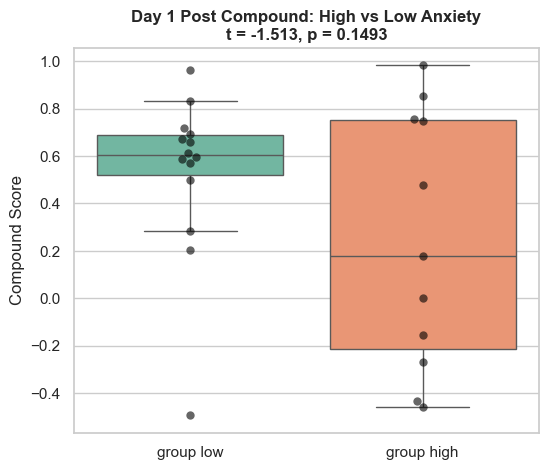

In [4]:
# T-test between high and low on day_1_post_compound
low_vals = df_merged[df_merged['Group'] == 'group low']['day_1_post_compound'].dropna()
high_vals = df_merged[df_merged['Group'] == 'group high']['day_1_post_compound'].dropna()

t_stat, p_val = stats.ttest_ind(high_vals, low_vals, equal_var=False)

print("=== Independent samples t-test (Welch's) ===")
print(f"Variable: day_1_post_compound")
print(f"Group Low  (N={len(low_vals)}): Mean = {low_vals.mean():.4f}, SD = {low_vals.std():.4f}")
print(f"Group High (N={len(high_vals)}): Mean = {high_vals.mean():.4f}, SD = {high_vals.std():.4f}")
print(f"t-statistic = {t_stat:.4f}")
print(f"p-value = {p_val:.4f}")

# Plot the comparison
plt.figure(figsize=(6, 5))
sns.boxplot(x='Group', y='day_1_post_compound', data=df_merged, palette='Set2', showfliers=False, order=['group low', 'group high'])
sns.swarmplot(x='Group', y='day_1_post_compound', data=df_merged, size=6, color='black', alpha=0.6, order=['group low', 'group high'])
plt.title(f"Day 1 Post Compound: High vs Low Anxiety\nt = {t_stat:.3f}, p = {p_val:.4f}", fontsize=12, fontweight='bold')
plt.xlabel("")
plt.ylabel("Compound Score")
plt.show()


In [5]:
corr_results = []
for colA, colB, label, labelA, labelB, delta_var in variables:
    df_valid = df_merged.dropna(subset=[delta_var, 'GAD7'])
    n = len(df_valid)
    if n > 2:
        r_pearson, p_pearson = stats.pearsonr(df_valid[delta_var], df_valid['GAD7'])
        r_spearman, p_spearman = stats.spearmanr(df_valid[delta_var], df_valid['GAD7'])
        corr_results.append({
            'Variable': delta_var,
            'Label': label,
            'N': n,
            'Pearson r': r_pearson,
            'Pearson p': p_pearson,
            'Spearman r': r_spearman,
            'Spearman p': p_spearman
        })
    else:
        corr_results.append({
            'Variable': delta_var,
            'Label': label,
            'N': n,
            'Pearson r': np.nan,
            'Pearson p': np.nan,
            'Spearman r': np.nan,
            'Spearman p': np.nan
        })

df_corr = pd.DataFrame(corr_results)
print("=== CORRELATION WITH GAD-7 ON EXTREMES SUBSET ===")
print(df_corr.to_string(index=False))


=== CORRELATION WITH GAD-7 ON EXTREMES SUBSET ===


      Variable                              Label  N  Pearson r  Pearson p  Spearman r  Spearman p
  DeltaDay1Pre              Day 1 Pre: Pos vs Neg 27  -0.426805   0.026403   -0.273378    0.167665
 DeltaDay1Post             Day 1 Post: Pos vs Neg 25  -0.112212   0.593321   -0.185336    0.375102
  DeltaDay2Pre              Day 2 Pre: Pos vs Neg 27  -0.149254   0.457465   -0.130712    0.515783
     DeltaDay1 Day 1: Post vs Pre Sentiment Delta 25   0.209263   0.315417    0.119136    0.570573
DeltaDay1_comp        Day 1 Compound: Post vs Pre 25   0.072062   0.732117    0.113315    0.589674
     DeltaPost      Post Compound: Day 2 vs Day 1 25   0.199522   0.338974    0.200629    0.336244


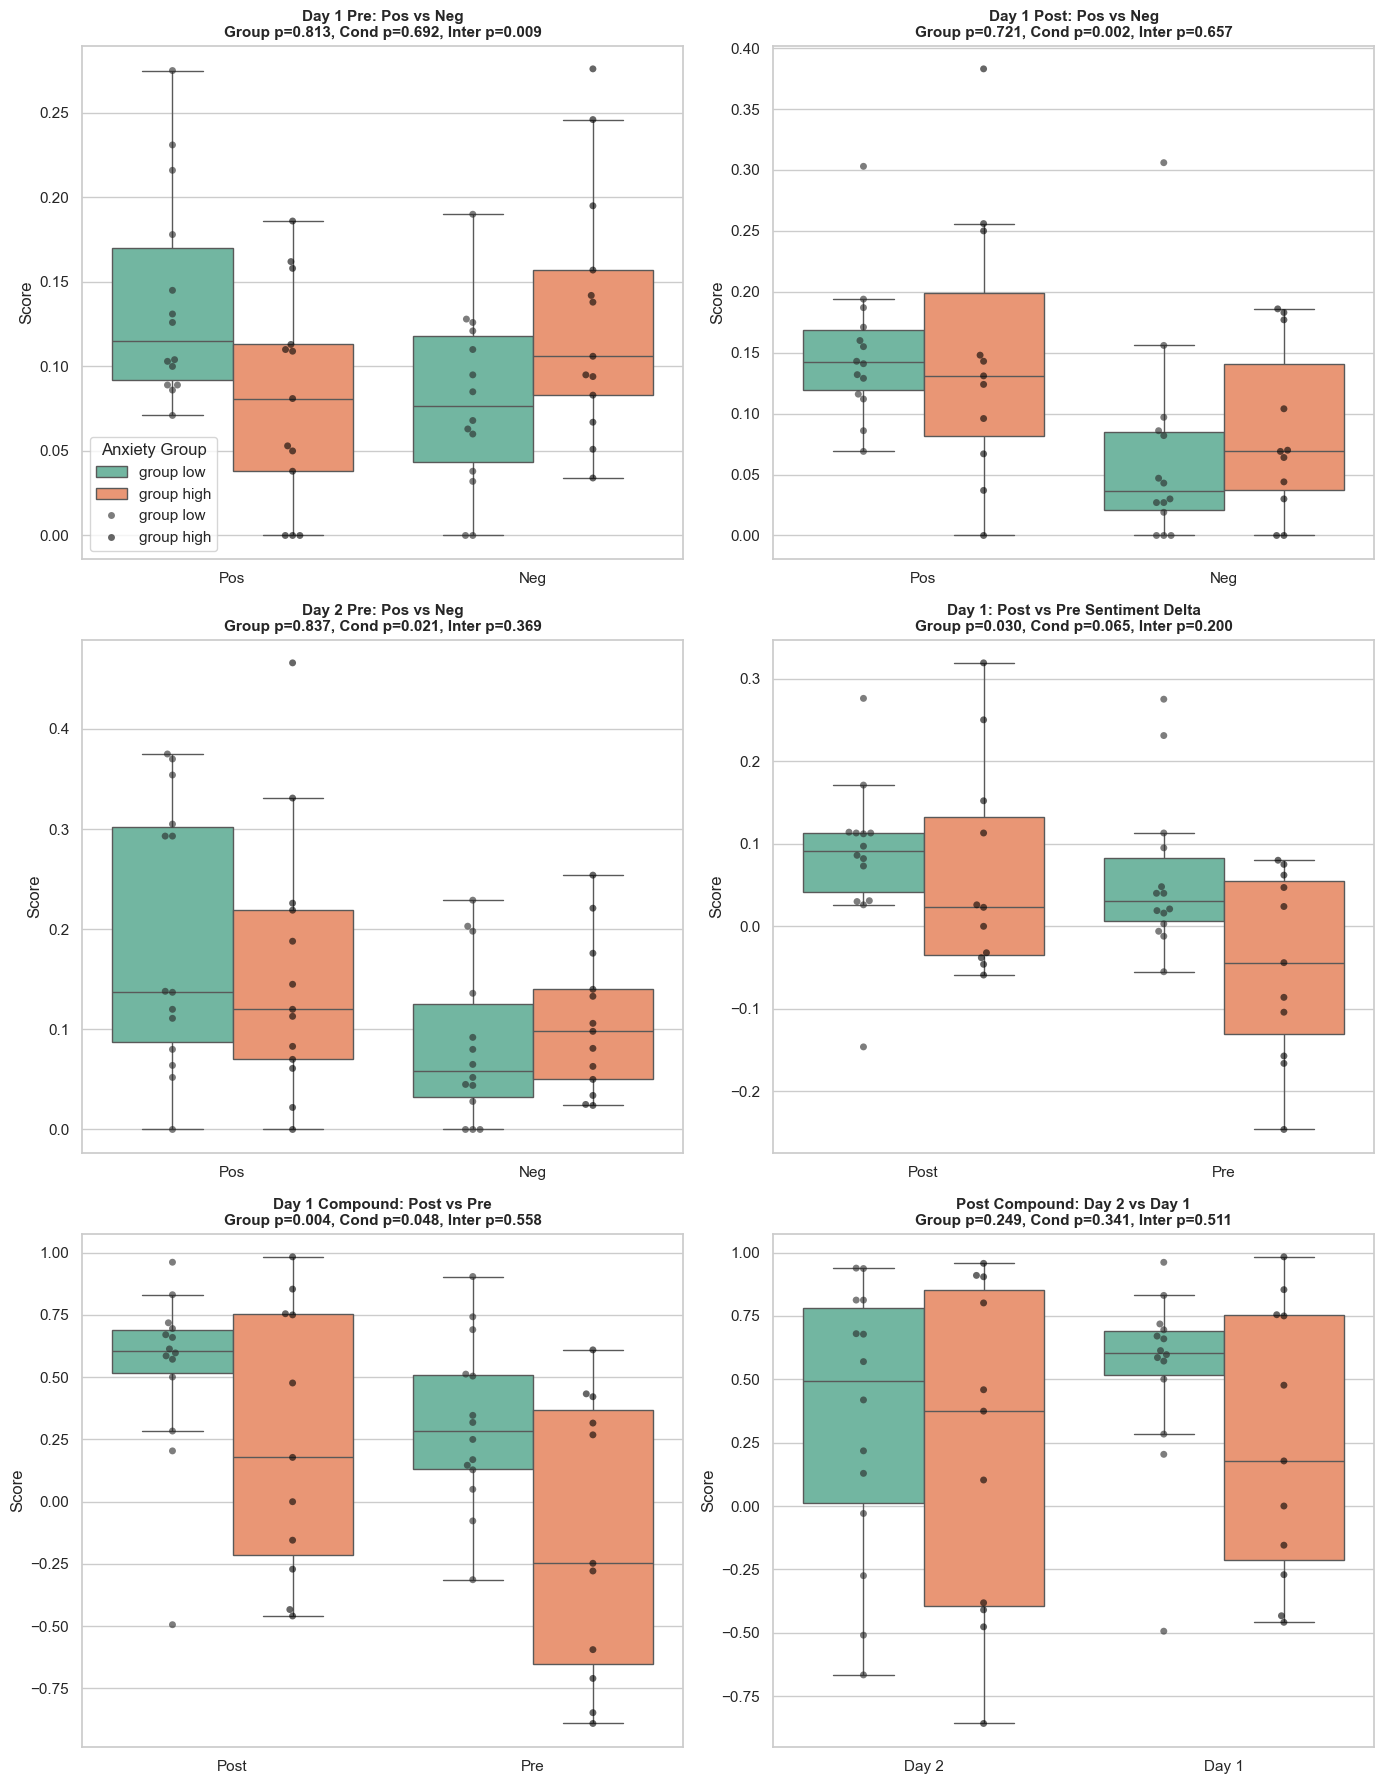

In [6]:
# Swarm/Box plots for Mixed ANOVA (Group x Condition)
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()

for i, (colA, colB, label, labelA, labelB, delta_var) in enumerate(variables):
    ax = axes[i]
    df_valid = df_merged.dropna(subset=[colA, colB])
    df_melt = df_valid.melt(id_vars=['Sub', 'Group'], value_vars=[colA, colB], var_name='Condition', value_name='Score')
    df_melt['Condition'] = df_melt['Condition'].map({colA: labelA, colB: labelB})
    
    # Plot boxplot + swarmplot comparing Group Low vs Group High across Conditions
    sns.boxplot(x='Condition', y='Score', hue='Group', data=df_melt, ax=ax, palette='Set2', showfliers=False, hue_order=['group low', 'group high'])
    sns.swarmplot(x='Condition', y='Score', hue='Group', data=df_melt, ax=ax, dodge=True, size=5, color='black', alpha=0.6, hue_order=['group low', 'group high'])
    
    # Extract ANOVA p-values (handling both 'p-unc' and 'p_unc' formatting depending on pingouin version)
    aov = anova_results[label]
    p_col = 'p-unc' if 'p-unc' in aov.columns else 'p_unc'
    p_group = aov.loc[aov['Source'] == 'Group', p_col].values[0]
    p_cond = aov.loc[aov['Source'] == 'Condition', p_col].values[0]
    p_inter = aov.loc[aov['Source'] == 'Interaction', p_col].values[0]
    
    ax.set_title(f"{label}\nGroup p={p_group:.3f}, Cond p={p_cond:.3f}, Inter p={p_inter:.3f}", fontsize=11, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    
    # Clean up legend (only show one)
    if i > 0:
         legend = ax.get_legend()
         if legend is not None:
             legend.remove()
    else:
        ax.legend(title='Anxiety Group')

plt.tight_layout()
plt.show()


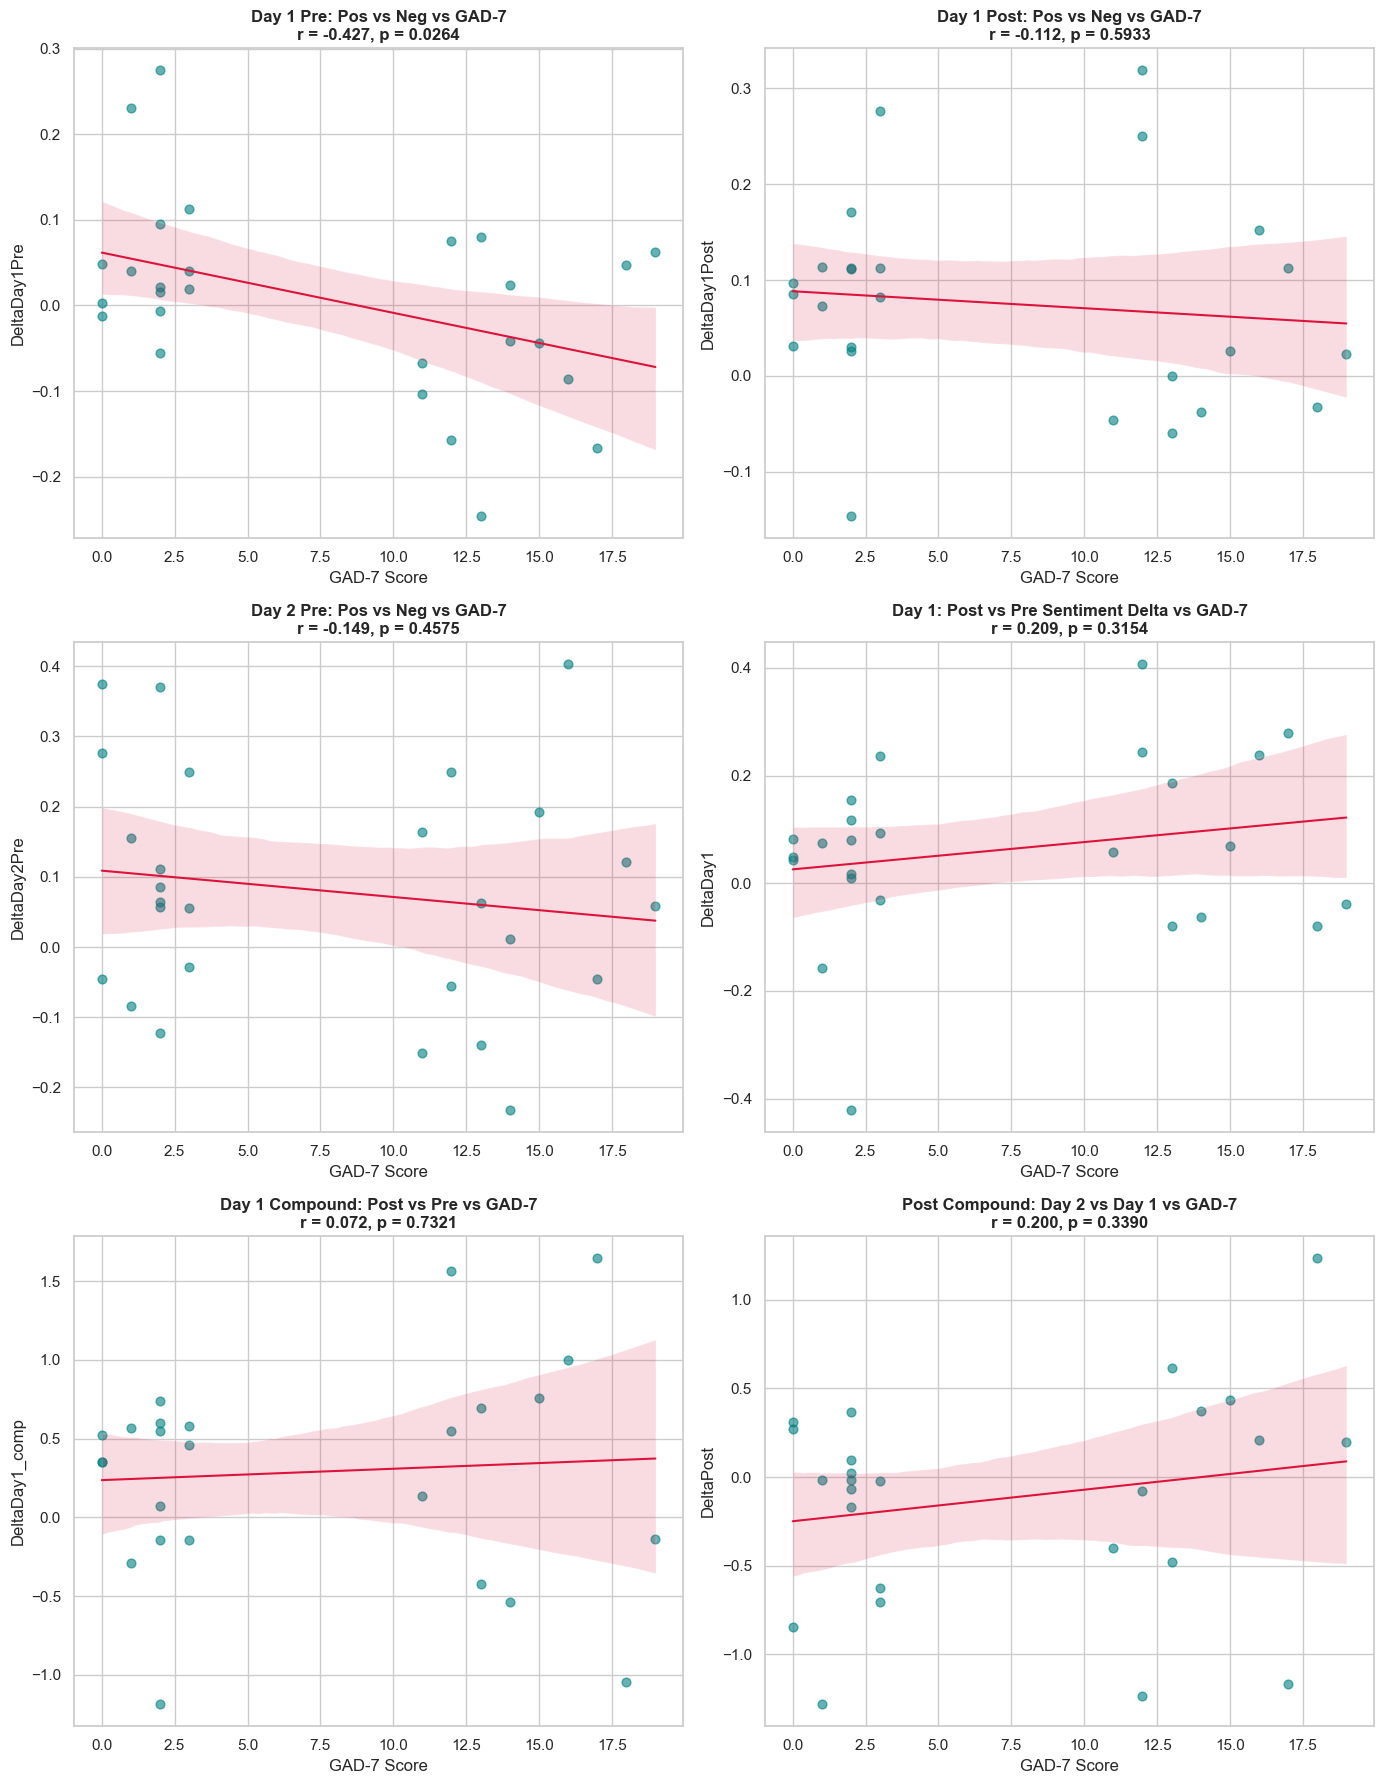

In [7]:
# Regplots for correlations with GAD-7
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()

for i, (colA, colB, label, labelA, labelB, delta_var) in enumerate(variables):
    ax = axes[i]
    df_valid = df_merged.dropna(subset=[delta_var, 'GAD7'])
    
    # Plot regplot
    sns.regplot(x='GAD7', y=delta_var, data=df_valid, ax=ax, color='teal', 
                scatter_kws={'alpha':0.6, 's':40}, line_kws={'color':'crimson', 'linewidth':1.5})
    
    r_val = df_corr.loc[df_corr['Variable'] == delta_var, 'Pearson r'].values[0]
    p_val = df_corr.loc[df_corr['Variable'] == delta_var, 'Pearson p'].values[0]
    
    ax.set_title(f"{label} vs GAD-7\nr = {r_val:.3f}, p = {p_val:.4f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("GAD-7 Score")
    ax.set_ylabel(delta_var)

plt.tight_layout()
plt.show()
